In [1]:
!pip install opencv-python
!pip install matplotlib
!pip install scipy
!pip install scikit-learn
!pip install focal_loss
!python -m pip install 'tensorflow[and-cuda]'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 48.1 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 23.3.1 -> 25.1.1
[notice] To update, run: python -m pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.6/106.6 kB 1.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 38.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 113.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 113.0 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 299.9 MB/s eta 0:00:00

[notice] A new release of pip is available: 23.3.1 -> 25.1.1
[notice] To update, run: python -m pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 821.0 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 61.6 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 23.3.1 -> 25.1.1
[not

In [2]:
!pip show tensorflow

Name: tensorflow
Version: 2.19.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: /usr/local/lib/python3.10/dist-packages
Requires: absl-py, astunparse, flatbuffers, gast, google-pasta, grpcio, h5py, keras, libclang, ml-dtypes, numpy, opt-einsum, packaging, protobuf, requests, setuptools, six, tensorboard, tensorflow-io-gcs-filesystem, termcolor, typing-extensions, wrapt
Required-by: focal-loss


In [3]:
!pwd

/workspace


In [12]:
# Dependency: 'apt update', 'apt install unrar'
!unrar x "/workspace/TuLane/training.rar"


UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from /workspace/TuLane/training.rar

Creating    training                                                  OK
Creating    training/gt_binary_image                                  OK
Extracting  training/gt_binary_image/0_0.png                             0  OK 
Extracting  training/gt_binary_image/0_10.png                            0  OK 
Extracting  training/gt_binary_image/0_100.png                           0  OK 
Extracting  training/gt_binary_image/0_1000.png                          0  OK 
Extracting  training/gt_binary_image/0_10002.png                         0  OK 
Extracting  training/gt_binary_image/0_10007.png                         0  OK 
Extracting  training/gt_binary_image/0_10012.png                         0  OK 
Extracting  training/gt_binary_image/0_10017.png                         0  OK 
Extracting  training/gt_binary_image/0_10022.png                         0  OK 
Extracting

# Start

In [2]:
import os
import os.path as ops

import cv2
from PIL import Image
import numpy as np
from matplotlib import pyplot as plt
import glob
import scipy
import shutil
import json

import tensorflow as tf
from tensorflow import keras
from tensorflow.python.keras import backend as K
from tensorflow.keras import models, layers, Sequential

In [3]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
config = tf.compat.v1.ConfigProto()
config.gpu_options.per_process_gpu_memory_fraction = 0.9  # Use 80% of the GPU memory
config.log_device_placement = True  # Log device placement for debugging
session = tf.compat.v1.Session(config=config)
K.set_session(session)

Device mapping:
/job:localhost/replica:0/task:0/device:GPU:0 -> device: 0, name: NVIDIA GeForce RTX 4090, pci bus id: 0000:02:00.0, compute capability: 8.9



I0000 00:00:1750255490.255148   35084 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 21696 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4090, pci bus id: 0000:02:00.0, compute capability: 8.9


# Preprocess Data & Load in RAM

In [5]:
def preprocessing(img_path, bin_path, resize=(512,256)):
    image_ds = []
    for i, image_name in enumerate(img_path):
        image = cv2.imread(image_name)
        image = Image.fromarray(image)
        image = image.resize(resize)
        image_ds.append(np.array(image, dtype=np.float32))
        
        # Show progress for loading into RAM
        if int((i % int(0.02*len(img_path)))) == 0 or i == (len(img_path) - 1):
            print(f'{i}/{len(img_path) - 1}', end = '\r' if i != (len(img_path) - 1) else '\n')
     
    mask_ds = []
    for i, image_name in enumerate(bin_path):
        image = cv2.imread(image_name, 0)
        image = Image.fromarray(image)
        image = image.resize(resize)
        label_binary = np.zeros([resize[1], resize[0]], dtype=np.uint8)
        mask = np.where(np.array(image)[:,:] != [0])
        #print(np.unique(np.array(image)))
        label_binary[mask] = 1
        mask_ds.append(np.array(label_binary, dtype=np.uint8))
        
        # Show progress for loading into RAM
        if int((i % int(0.02*len(bin_path)))) == 0 or i == (len(bin_path) - 1):
            print(f'{i}/{len(bin_path) - 1}', end = '\r' if i != (len(bin_path) - 1) else '\n')
        
    return image_ds, mask_ds

In [6]:
w_dir = os.getcwd()
src_dir = ops.join(w_dir, ops.join('TuLane','splits'))
training_fp = ops.join(ops.split(src_dir)[0], 'training')

img_fp = ops.join(training_fp, 'gt_image')
img_clahe_fp = ops.join(training_fp, 'clahe_gt_image')
bin_fp = ops.join(training_fp, 'gt_binary_image')

flag_CLAHE = False
if flag_CLAHE == True:
    img_path = glob.glob(ops.join(img_clahe_fp, "*.png"))
else:
    img_path = glob.glob(ops.join(img_fp, "*.png"))
bin_path = glob.glob(ops.join(bin_fp, "*.png"))

In [7]:
image_ds, mask_ds = preprocessing(img_path, bin_path)
print("Image Dataset size:", len(image_ds))
print("Mask Dataset size:", len(mask_ds))

6554/6554
6554/6554
Image Dataset size: 6555
Mask Dataset size: 6555


In [8]:
from sklearn.model_selection import train_test_split

tf.random.set_seed(40)
X_train, X_test, bin_train, bin_test = train_test_split(image_ds, mask_ds, test_size = 0.15, random_state=0)

In [9]:
X_train = np.array(X_train)
X_test = np.array(X_test)
bin_train = np.array(bin_train)
bin_test = np.array(bin_test)

# Fix for BinaryFocalLoss
bin_train = np.expand_dims(bin_train, axis=-1)    # Add a channel dimension
bin_test = np.expand_dims(bin_test, axis=-1)    # Add a channel dimension

print(X_train.shape)
print(X_test.shape)
print(bin_train.shape)
print(bin_test.shape)

(5571, 256, 512, 3)
(984, 256, 512, 3)
(5571, 256, 512, 1)
(984, 256, 512, 1)


# DNN - UNet

In [10]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Rescaling, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout, ReLU, Lambda

################################################################
def simple_unet_model(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS):
#Build the model
    inputs = Input((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
    #s = Lambda(lambda x: x / 255.0)(inputs)   #No need for this if we normalize our inputs beforehand
    s = inputs

    #Contraction path
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(s)
    c1 = Dropout(0.1)(c1)
    c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c1)
    p1 = MaxPooling2D((2, 2))(c1)
    
    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p1)
    c2 = Dropout(0.1)(c2)
    c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)
     
    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p2)
    c3 = Dropout(0.2)(c3)
    c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c3)
    p3 = MaxPooling2D((2, 2))(c3)
     
    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p3)
    c4 = Dropout(0.2)(c4)
    c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c4)
    p4 = MaxPooling2D(pool_size=(2, 2))(c4)
     
    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p4)
    c5 = Dropout(0.3)(c5)
    c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c5)
    
    #Expansive path bin
    u6_bin = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c5)
    u6_bin = concatenate([u6_bin, c4])
    c6_bin = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u6_bin)
    c6_bin = Dropout(0.2)(c6_bin)
    c6_bin = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c6_bin)
     
    u7_bin = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c6_bin)
    u7_bin = concatenate([u7_bin, c3])
    c7_bin = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u7_bin)
    c7_bin = Dropout(0.2)(c7_bin)
    c7_bin = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c7_bin)
     
    u8_bin = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c7_bin)
    u8_bin = concatenate([u8_bin, c2])
    c8_bin = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u8_bin)
    c8_bin = Dropout(0.1)(c8_bin)
    c8_bin = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c8_bin)
     
    u9_bin = Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(c8_bin)
    u9_bin = concatenate([u9_bin, c1], axis=3)
    c9_bin = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u9_bin)
    c9_bin = Dropout(0.1)(c9_bin)
    c9_bin = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c9_bin)
     
    bin_seg = Conv2D(1, (1, 1), activation='sigmoid', name='bin_seg')(c9_bin)
     
    model = Model(inputs=inputs, outputs=bin_seg)
    
    return model

In [11]:
# External keras dependencies
from focal_loss import BinaryFocalLoss
# def iou(y_true, y_pred):
#     def f(y_true, y_pred):
#         intersection = (y_true * y_pred).sum()
#         union = y_true.sum() + y_pred.sum() - intersection
#         x = (intersection + 1e-15) / (union + 1e-15)
#         x = x.astype(np.float32)
#         return x
#     return tf.numpy_function(f, [y_true, y_pred], tf.float32)


def iou(y_true, y_pred):
    def f(y_true, y_pred):
        y_true = tf.cast(y_true, dtype=tf.float32)
        intersection = tf.reduce_sum(y_true * y_pred)
        union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
        x = (intersection + 1e-15) / (union + 1e-15)
        x = tf.cast(x, dtype=tf.float32)
        return x
    return f(y_true,y_pred)

In [12]:
retrain = False

if retrain == False:
    model = simple_unet_model(256, 512, 3)
    model.summary()
else:
    model_number = 1
    cwd = os.getcwd()
    load_path = ops.join(cwd, ops.join('output', 'final'))
    model_path = ops.join(load_path, os.listdir(load_path)[model_number])
    hdf5_path = ops.join(model_path, [file for file in os.listdir(model_path) if file.endswith('.hdf5')][0])
    print(hdf5_path)
    model = keras.models.load_model(hdf5_path, custom_objects={'iou':iou})
    model.summary()

I0000 00:00:1750255729.595300   35084 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 21696 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4090, pci bus id: 0000:02:00.0, compute capability: 8.9


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 512,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256, 512,  │          0 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 512,  │      2,320 │ dropout[0][0]     │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 256,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 256,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128, 256,  │          0 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 256,  │      9,248 │ dropout_1[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 128,   │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 128,   │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 128,   │          0 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 128,   │     36,928 │ dropout_2[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 64,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 64,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32, 64,    │          0 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 64,    │    147,584 │ dropout_3[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 32,    │          0 │ conv2d_7[0][0]  

 Total params: 1,941,105 (7.40 MB)

 Trainable params: 1,941,105 (7.40 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from focal_loss import BinaryFocalLoss
from tensorflow.keras.callbacks import TerminateOnNaN
from tensorflow.keras.callbacks import ModelCheckpoint
import datetime
import pickle

LR = 1e-4                      # Learning rate
EPOCHS = 200                   # Number of epochs
BS = 16                        # Number of batch size
LossWeights = float(10)        # Loss function weights for Binary Segmentation and Instance Segmentation
terminate = TerminateOnNaN()   # Terminate the training process if the loss reaches NaN
# es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=0)                   #Early Stopping if model overfits
log_dir = "./logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")               #Save path for tensorboard
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)  #Tensorboard
filepath = "./output/saved-model.weights.h5"  #save path for the checkpoint function
checkpoint = ModelCheckpoint(filepath, monitor='loss', verbose=1, save_best_only=True,    #Checkpoint every epoch
                             save_weights_only=True, mode='auto', save_freq='epoch')

tf.random.set_seed(40)
optimizer = tf.keras.optimizers.Adam(learning_rate=LR, decay=LR/100)   #Optimizer configuration
model.compile(optimizer=optimizer,
              loss=BinaryFocalLoss(gamma=2),
              loss_weights=LossWeights,
              metrics=[iou])

history = model.fit(X_train, bin_train,
                    batch_size = BS,
                    verbose=1,
                    epochs=EPOCHS,
                    validation_data=(X_test, bin_test),
                    shuffle=False,
                    callbacks=[terminate, tensorboard_callback, checkpoint])

/usr/local/lib/python3.10/dist-packages/keras/src/optimizers/base_optimizer.py:86: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


Epoch 1/200


I0000 00:00:1750255953.839879   35268 service.cc:152] XLA service 0x7f9d3c0254a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1750255953.839899   35268 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 4090, Compute Capability 8.9
2025-06-18 14:12:33.937395: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1750255954.329175   35268 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/349 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - iou: 0.0231 - loss: 53.8936   

I0000 00:00:1750255962.937426   35268 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


349/349 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - iou: 0.0027 - loss: 7.1007
Epoch 1: loss improved from inf to 4.51249, saving model to ./output/saved-model.weights.h5
349/349 ━━━━━━━━━━━━━━━━━━━━ 38s 79ms/step - iou: 0.0027 - loss: 7.0933 - val_iou: 3.9779e-04 - val_loss: 3.8540
Epoch 2/200
347/349 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - iou: 3.0071e-04 - loss: 3.8640
Epoch 2: loss improved from 4.51249 to 3.86665, saving model to ./output/saved-model.weights.h5
349/349 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - iou: 3.0146e-04 - loss: 3.8640 - val_iou: 7.7276e-04 - val_loss: 3.8435
Epoch 3/200
347/349 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - iou: 7.4015e-04 - loss: 3.8488
Epoch 3: loss improved from 3.86665 to 3.84746, saving model to ./output/saved-model.weights.h5
349/349 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - iou: 7.4162e-04 - loss: 3.8488 - val_iou: 0.0013 - val_loss: 3.7999
Epoch 4/200
347/349 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - iou: 0.0060 - loss: 3.5632
Epoch 4: loss improved from 3.84746 to 2.7131

In [14]:
if not ops.exists('./output/final'):
    os.makedirs('./output/final', exist_ok=True)
np.save('./output/final/RTX4090_Model1_200Epochs.npy',history.history)                   #Save the training loss, acc, and meanIou
model.save('./output/final/RTX4090_Model1_200Epochs_hdf5format.h5')                      #Save the trained weight
model.save('./output/final/RTX4090_Model1_200Epochs_h5format.keras')                     #Save the trained weight

In [15]:
preds = model.predict(X_test[0:10])
preds.max(), preds.min()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


(np.float32(0.99994016), np.float32(0.0))

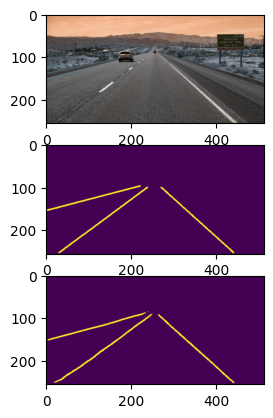

In [16]:
## print(preds.shape)

preds2 = (preds >= (preds.max() * 0.5)).astype(int)
idx = 0
plt.subplot(3,1,1)
plt.imshow(X_test[idx]/255.)
plt.subplot(3,1,2)
plt.imshow(bin_test[idx])
plt.subplot(3,1,3)
plt.imshow(preds2[idx])

Text(0.5, 1.0, 'Loss')

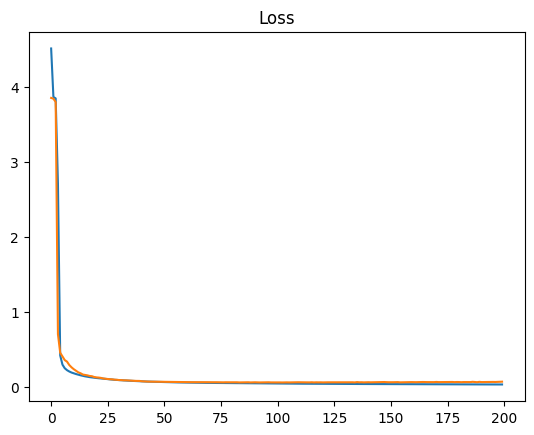

In [17]:
# Vizualizarea loss-ului
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")

Text(0.5, 1.0, 'IoU')

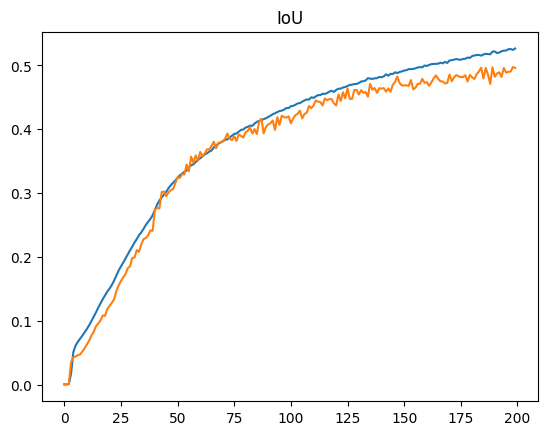

In [18]:
# Vizualizarea iou-ului
plt.plot(history.history['iou'])
plt.plot(history.history['val_iou'])
plt.title("IoU")